# M13.3a — Evaluación de R1/R2/R3 frente a M11 (val)

Entradas (solo lectura): npz de val de M11 final G1 y, para `M13_3a_R1_s123`, `M13_3a_R2_s123` y `M13_3a_R3_s124`,
`val_predictions_embeddings.npz`, `train40k_predictions.npz` y `history.npz` en `<data_root>/results/M13_3/<tag>/`.
Escalador train-only y split del contrato congelado G1 (`g1_npe_contract.load_contract`, config M11).
Del HDF5 G1 solo se leen `file_group_id` y `target_network_snr` en las filas de val. Ni X, ni cal ni test.

Convenciones: etiquetas [chirp_mass, total_mass, chi_eff]; unidades físicas; residuo r = f − θ (predicción menos verdad);
“pendiente θ sobre f” = OLS de la verdad sobre la predicción (≈ 1 si calibrado), como en `history.npz`.
Épocas 0-based, como en `history.npz`. Solo validación: esto no es una evaluación en test.

Salida única: `<data_root>/results/M13_3/M13_3a_evaluation_summary.json` (modo `'x'`; aborta si existe).

In [1]:
import json
import sys
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENTS.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root
# Read-only reuse of the pinned contract, the exact C3 implementation of M12.5.3 and tau of M13.1.
from scripts.m12.m12_5_3_posthoc_check import (
    ALPHAS, DATASET, FAMILY_ALPHA, LABELS, MARGIN_FRAC, bootstrap_means, decide, digest,
    load_contract, npz_to_physical, require, ridge_paths, select_inner, slope_row)
from scripts.m13.m13_1_diagnostics import corr_row, tau_newtonian

cfg = json.loads((ROOT / 'configs/experiments/train_m11_final_G1_500k.json').read_text())
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
M11_NPZ = DATA_ROOT / 'results' / DATASET / 'm11_final_G1_500k_val_predictions_embeddings.npz'
M13_DIR = DATA_ROOT / 'results' / 'M13_3'
TAGS = {'R1': 'M13_3a_R1_s123', 'R2': 'M13_3a_R2_s123', 'R3': 'M13_3a_R3_s124'}
NEW = list(TAGS)
MODELS = ['M11'] + NEW
SEED_PAIR = ('R2', 'R3')  # same recipe, different seed -> seed-noise proxy
SUMMARY_PATH = M13_DIR / 'M13_3a_evaluation_summary.json'

# Fixed settings (prompt M13.3a).
Y_RTOL = 1e-5                   # y equality across npz: |dy| <= rtol*|y| + rtol*y_std (float32 round trip)
GUARD_PCT = 2.0                 # RMSE guardrail vs M11, % per label
N_BOOT_ROWS, SEED_ROWS = 2000, 133500
EPOCH_MARK, SLOPE_EPOCHS = 64, (63, 79)
P1_RANGE, P2_MAX = (0.99, 1.01), 1.02
C3_N_BOOT, C3_SEED = 2000, 125301   # M12.5.3 protocol
P3_MAX_FRAC = 0.01
P4_MIN_SAME = 8
SNR_EDGES = np.linspace(10.0, 25.0, 6)  # 5 equal-width bins, last closed
COLORS = {'M11': 'k', 'R1': 'tab:blue', 'R2': 'tab:orange', 'R3': 'tab:green'}

require(not SUMMARY_PATH.exists(), f'Summary already exists: {SUMMARY_PATH}')
print(DATA_ROOT)

/data/vserrano/cbc_pe_data


## 0. Integridad
SHA256 de cada npz; contrato G1; mismas `idx` de val (= pertenencia a val) y misma `y` en todos los modelos; mismo subconjunto
train40k en R1/R2/R3. Cualquier fallo aborta. Todas las filas se ordenan por `idx` ascendente para el emparejamiento.

In [2]:
paths, splits, c_mean, c_std, identity = load_contract(DATA_ROOT)
files = {'M11_val': M11_NPZ}
for r, tag in TAGS.items():
    for kind, name in (('val', 'val_predictions_embeddings.npz'), ('train40k', 'train40k_predictions.npz'),
                       ('history', 'history.npz')):
        files[f'{r}_{kind}'] = M13_DIR / tag / name
missing = [str(p) for p in files.values() if not p.exists()]
require(not missing, f'Missing inputs: {missing}')
sha = {k: digest(p) for k, p in files.items()}

checks = ['frozen G1 contract (g1_npe_contract.load_contract)']
def check(ok, name):
    require(bool(ok), 'Check failed: ' + name)
    checks.append(name)


def load_pred(path, split, name):
    # model_config / input_normalization are object arrays and are never accessed.
    with np.load(path, allow_pickle=False) as a:
        f, y = (a[k].astype(np.float64) for k in (f'pred_{split}', f'y_{split}'))
        emb = a[f'emb_{split}'].astype(np.float64)
        idx = a[f'idx_{split}'].astype(np.int64)
        y_mean, y_std = a['y_mean'].astype(np.float64), a['y_std'].astype(np.float64)
        label_names = a['label_names'].tolist()
        split_name = Path(str(a['split_path'])).name
        snr_keys = [k for k in a.files if 'snr' in k.lower()]
    n = len(idx)
    check(f.shape == y.shape == (n, 3) and emb.shape[0] == n, f'{name}: shapes')
    check(label_names == LABELS, f'{name}: label order {LABELS}')
    check(split_name == paths['split_file'].name, f'{name}: split_path is the pinned split file')
    check(np.allclose(y_mean, c_mean, rtol=1e-6) and np.allclose(y_std, c_std, rtol=1e-6, atol=1e-8),
          f'{name}: npz y_mean/y_std equal train-only label stats')
    check(len(np.unique(idx)) == n, f'{name}: idx without duplicates')
    check(all(np.isfinite(v).all() for v in (f, y, emb)), f'{name}: finite values')
    # Train-only scaler of the M11 contract; M13.3 standardizes with y_std + 1e-8 (relative effect ~1e-9).
    y, f, units = npz_to_physical(y, f, c_mean, c_std)
    check(np.all(np.abs(f.mean(0) - y.mean(0)) < 0.1 * c_std), f'{name}: pred in units of y ({units})')
    o = np.argsort(idx)
    return dict(f=f[o], y=y[o], emb=emb[o], idx=idx[o], units=units, snr_keys=snr_keys)


val = {'M11': load_pred(M11_NPZ, 'val', 'M11 val')}
tr40 = {}
for r in NEW:
    val[r] = load_pred(files[f'{r}_val'], 'val', f'{r} val')
    tr40[r] = load_pred(files[f'{r}_train40k'], 'train', f'{r} train40k')

IDX, Y = val['M11']['idx'], val['M11']['y']
check(np.array_equal(IDX, splits['val']), 'M11 idx_val equals val membership')
for m in NEW:
    check(np.array_equal(val[m]['idx'], IDX), f'{m}: same val idx as M11')
    dy = np.abs(val[m]['y'] - Y)
    print(f'{m}: max |y - y_M11| =', dy.max(0))
    check(np.all(dy <= Y_RTOL * np.abs(Y) + Y_RTOL * c_std), f'{m}: same val y as M11 (rtol {Y_RTOL:g})')
IDX_TR, Y_TR = tr40['R1']['idx'], tr40['R1']['y']
check(np.all(np.isin(IDX_TR, splits['train'])), 'train40k idx within train membership')
for m in NEW[1:]:
    check(np.array_equal(tr40[m]['idx'], IDX_TR), f'{m}: same train40k idx as R1')
    check(np.all(np.abs(tr40[m]['y'] - Y_TR) <= Y_RTOL * np.abs(Y_TR) + Y_RTOL * c_std),
          f'{m}: same train40k y as R1')

P = {m: val[m]['f'] for m in MODELS}
P_TR = {m: tr40[m]['f'] for m in NEW}
EMB = {m: val[m]['emb'] for m in MODELS}

hist = {}
for r in NEW:
    with np.load(files[f'{r}_history'], allow_pickle=False) as a:
        hist[r] = {k: a[k] for k in a.files}
    h = hist[r]
    check(h['label_names'].tolist() == LABELS, f'{r}: history label order')
    E = len(h['epoch'])
    check(all(h[k].shape == (E, 3) for k in ('val_mse', 'val_slope', 'train40k_mse', 'train40k_slope')),
          f'{r}: history shapes')
    off = np.flatnonzero(h['dropout_off'].astype(bool))
    print(f"{r}: epochs {int(h['epoch'][0])}..{int(h['epoch'][-1])}, first dropout-off epoch:",
          int(h['epoch'][off[0]]) if off.size else None)

# Per-row metadata: npz first, otherwise only two HDF5 columns at the (sorted) val rows.
snr_key = next((k for m in MODELS for k in val[m]['snr_keys']), None)
with h5py.File(paths['dataset_file'], 'r') as h:
    require('file_group_id' in h, 'HDF5 lacks file_group_id')
    ENV = h['file_group_id'][IDX]
    if snr_key is None and 'target_network_snr' in h:
        SNR, snr_source = h['target_network_snr'][IDX].astype(np.float64), 'HDF5 target_network_snr'
    else:
        SNR, snr_source = None, None
if snr_key is not None:
    m_src = next(m for m in MODELS if snr_key in val[m]['snr_keys'])
    with np.load(files['M11_val' if m_src == 'M11' else f'{m_src}_val'], allow_pickle=False) as a:
        snr_idx = a[f'idx_val'].astype(np.int64)
        SNR, snr_source = a[snr_key].astype(np.float64)[np.argsort(snr_idx)], f'npz {m_src}:{snr_key}'
check(len(np.unique(ENV)) >= 3, 'at least 3 environments in val')
print('SNR source:', snr_source, '| envs:', len(np.unique(ENV)))
pd.Series(sha, name='sha256').to_frame()

R1: max |y - y_M11| = [0. 0. 0.]
R2: max |y - y_M11| = [0. 0. 0.]
R3: max |y - y_M11| = [0. 0. 0.]
R1: epochs 0..79, first dropout-off epoch: None
R2: epochs 0..79, first dropout-off epoch: 64
R3: epochs 0..79, first dropout-off epoch: 64
SNR source: HDF5 target_network_snr | envs: 3


,sha256
M11_val,586b95f2cb2cfaf150fbdd05760f50f47a95a555451fcb...
R1_val,c217f2e60ac04ec6c2a36ce7f383b86dbe7a18cf816424...
R1_train40k,c76a006e11c1fa14575df8123d9e6963ad64fb9299ec65...
R1_history,c00bae849587e26c5e9c4684cfcbbb18a717503d471e9b...
R2_val,2efe994d8dd9f81a497971cd3f034fd3b35e70982bb066...
R2_train40k,705279c4f97fac63315704569399a67d4492e9f93e133a...
R2_history,43b8a68578200ff56cbcf6451c272771e0f692323be681...
R3_val,ea0bcafd5f62f11e5b506c431d5193fc1bb1dd40369dda...
R3_train40k,537056ba13298a015a6486939f4daddfc7dc7256c7aa60...
R3_history,6404bc6ef7c33dae88c2effb5bdabb388fb23d0321af0f...


## 1. Métricas globales por etiqueta (unidades físicas)
Δ% = 100·(RMSE/RMSE_M11 − 1). Ruido de semilla = |Δ%_R2 − Δ%_R3|; “resuelto” si |Δ%| > 2·ruido. Salvaguarda: Δ% ≤ +2 %.
El IC 95 % de bootstrap emparejado por filas (mismos remuestreos para todos los modelos) mide **solo** la incertidumbre de
muestreo de filas de val, **no** la variación entre semillas.

In [3]:
def label_metrics(f, y):
    rows = []
    for j, lab in enumerate(LABELS):
        e, s = f[:, j] - y[:, j], slope_row(f[:, j], y[:, j])
        rows.append(dict(label=lab, rmse=np.sqrt(np.mean(e**2)), mae=np.mean(np.abs(e)), r2=s['r2'],
                         slope_theta_on_f=s['slope_truth_on_pred'],
                         intercept_theta_on_f=s['intercept_truth_on_pred'],
                         slope_f_on_theta=s['slope_pred_on_truth']))
    return rows


tab1 = pd.DataFrame([dict(model=m, **row) for m in MODELS for row in label_metrics(P[m], Y)])
rmse = tab1.pivot(index='model', columns='label', values='rmse')[LABELS]
dpct = 100.0 * (rmse / rmse.loc['M11'] - 1.0)
seed_noise = (dpct.loc[SEED_PAIR[0]] - dpct.loc[SEED_PAIR[1]]).abs()
tab1['delta_rmse_pct'] = [dpct.loc[m, l] for m, l in zip(tab1.model, tab1.label)]
tab1['seed_noise_pct'] = [np.nan if m == 'M11' else seed_noise[l] for m, l in zip(tab1.model, tab1.label)]
tab1['resolved'] = [None if m == 'M11' else bool(abs(d) > 2 * s)
                    for m, d, s in zip(tab1.model, tab1.delta_rmse_pct, tab1.seed_noise_pct)]
tab1['guardrail'] = [None if m == 'M11' else ('PASA' if d <= GUARD_PCT else 'FALLA')
                     for m, d in zip(tab1.model, tab1.delta_rmse_pct)]

# Paired row bootstrap of RMSE_model - RMSE_M11 (shared resamples).
rng = np.random.default_rng(SEED_ROWS)
n = len(Y)
se = {m: (P[m] - Y)**2 for m in MODELS}
boot = {m: np.empty((N_BOOT_ROWS, 3)) for m in MODELS}
for start in range(0, N_BOOT_ROWS, 50):
    b = min(50, N_BOOT_ROWS - start)
    w = rng.multinomial(n, np.full(n, 1.0 / n), size=b).astype(np.float64)
    for m in MODELS:
        boot[m][start:start + b] = np.sqrt(w @ se[m] / n)
rows = []
for m in NEW:
    d = boot[m] - boot['M11']
    lo, hi = np.percentile(d, [2.5, 97.5], axis=0)
    for j, lab in enumerate(LABELS):
        base = rmse.loc['M11', lab]
        rows.append(dict(model=m, label=lab, d_rmse=rmse.loc[m, lab] - base, ci95_lo=lo[j], ci95_hi=hi[j],
                         d_rmse_pct=dpct.loc[m, lab], ci95_lo_pct=100 * lo[j] / base, ci95_hi_pct=100 * hi[j] / base))
tab1_boot = pd.DataFrame(rows)
tab1_boot['uncertainty'] = 'row sampling (val), not seed'
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab1)
    display(tab1_boot)

,model,label,rmse,mae,r2,slope_theta_on_f,intercept_theta_on_f,slope_f_on_theta,delta_rmse_pct,seed_noise_pct,resolved,guardrail
0,M11,chirp_mass,5.8274,3.9494,0.8755,1.0508,-1.9814,0.83514,0,NaN,None,None
1,M11,total_mass,10.598,7.5436,0.9067,1.0585,-5.9496,0.85932,0,NaN,None,None
2,M11,chi_eff,0.19433,0.14528,0.80404,1.0377,0.0055587,0.77601,0,NaN,None,None
3,R1,chirp_mass,5.7737,3.7762,0.87778,1.0054,0.13487,0.87346,-0.92078,1.2639,False,PASA
4,R1,total_mass,10.472,7.2227,0.9089,1.0156,-0.86912,0.89543,-1.1901,1.6899,False,PASA
5,R1,chi_eff,0.19467,0.14445,0.80336,1.0142,-0.020463,0.79437,0.17511,0.21086,False,PASA
6,R2,chirp_mass,5.7682,3.7459,0.87801,0.98109,0.78347,0.89529,-1.0147,1.2639,False,PASA
7,R2,total_mass,10.391,7.1535,0.9103,0.98728,1.1889,0.92218,-1.9523,1.6899,False,PASA
8,R2,chi_eff,0.19495,0.14398,0.80279,0.97519,-0.00033115,0.82374,0.32036,0.21086,False,PASA
9,R3,chirp_mass,5.8419,3.7611,0.87488,0.97902,0.88204,0.89407,0.24912,1.2639,False,PASA


,model,label,d_rmse,ci95_lo,ci95_hi,d_rmse_pct,ci95_lo_pct,ci95_hi_pct,uncertainty
0,R1,chirp_mass,-0.053657,-0.10514,-0.00055547,-0.92078,-1.8042,-0.0095321,"row sampling (val), not seed"
1,R1,total_mass,-0.12612,-0.24313,-0.0024852,-1.1901,-2.2942,-0.023451,"row sampling (val), not seed"
2,R1,chi_eff,0.00034029,-0.00089548,0.0015468,0.17511,-0.4608,0.79597,"row sampling (val), not seed"
3,R2,chirp_mass,-0.059132,-0.11025,-0.0069833,-1.0147,-1.892,-0.11984,"row sampling (val), not seed"
4,R2,total_mass,-0.2069,-0.32764,-0.090605,-1.9523,-3.0917,-0.85495,"row sampling (val), not seed"
5,R2,chi_eff,0.00062256,-0.00071941,0.0019795,0.32036,-0.3702,1.0186,"row sampling (val), not seed"
6,R3,chirp_mass,0.014517,-0.042033,0.072336,0.24912,-0.72131,1.2413,"row sampling (val), not seed"
7,R3,total_mass,-0.027812,-0.15384,0.10769,-0.26244,-1.4516,1.0161,"row sampling (val), not seed"
8,R3,chi_eff,0.0002128,-0.0011784,0.0014288,0.10951,-0.60638,0.73524,"row sampling (val), not seed"


## 2. Dinámica de entrenamiento
MSE (unidades estandarizadas) y pendiente θ sobre f por época, en val (continua) y train40k (discontinua). Línea vertical en la
época 64 (0-based).

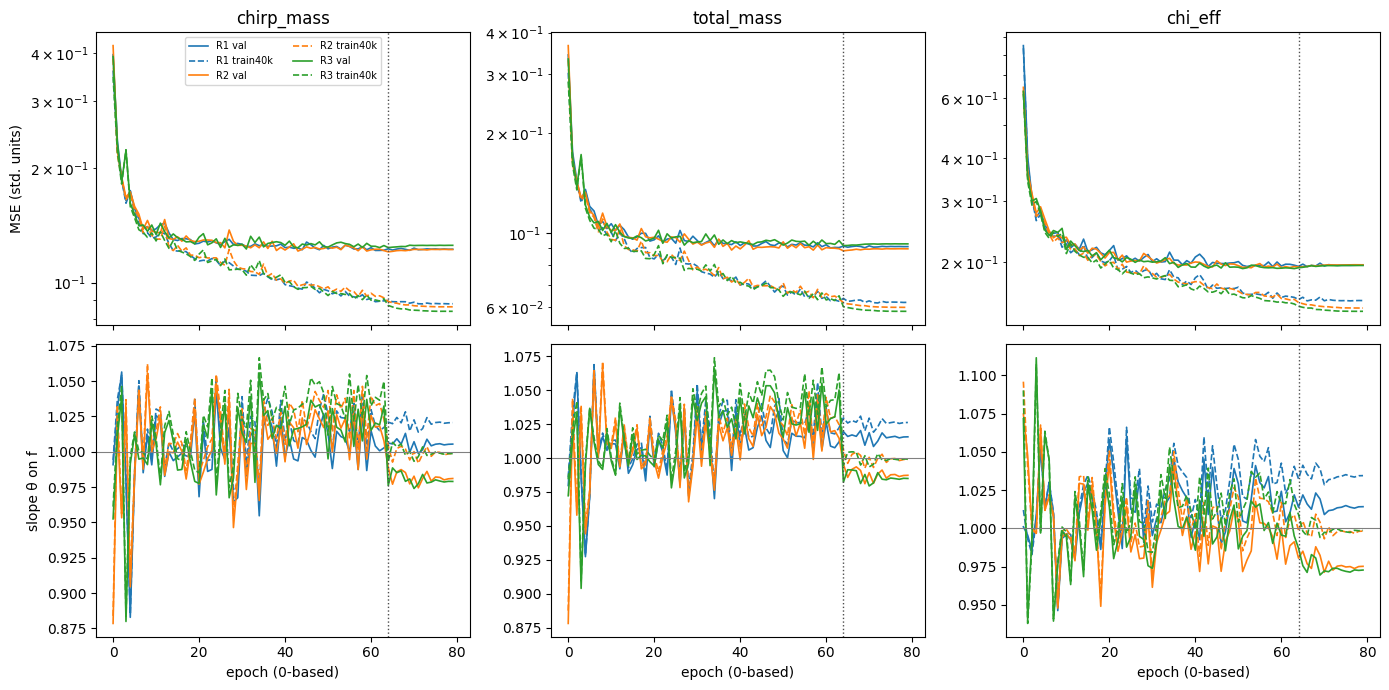

,model,epoch,chirp_mass,total_mass,chi_eff
0,R1,63,1.017208,1.022361,1.040543
1,R1,79,1.020692,1.026202,1.034460
2,R2,63,1.023028,1.024685,1.008859
3,R2,79,0.998751,0.999032,0.998198
4,R3,63,1.049832,1.062831,1.015788
5,R3,79,0.998734,0.999199,0.998701


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for r in NEW:
    h, ep = hist[r], hist[r]['epoch']
    for j, lab in enumerate(LABELS):
        for key, ls in (('val', '-'), ('train40k', '--')):
            axes[0, j].plot(ep, h[f'{key}_mse'][:, j], ls, color=COLORS[r], lw=1.2, label=f'{r} {key}')
            axes[1, j].plot(ep, h[f'{key}_slope'][:, j], ls, color=COLORS[r], lw=1.2)
for j, lab in enumerate(LABELS):
    axes[0, j].set(title=lab, yscale='log')
    axes[1, j].axhline(1.0, color='0.5', lw=0.8)
    axes[1, j].set(xlabel='epoch (0-based)')
    for ax in axes[:, j]:
        ax.axvline(EPOCH_MARK, color='0.3', ls=':', lw=1)
axes[0, 0].set_ylabel('MSE (std. units)')
axes[1, 0].set_ylabel('slope θ on f')
axes[0, 0].legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

rows = []
for r in NEW:
    ep = hist[r]['epoch']
    for e in SLOPE_EPOCHS:
        i = np.flatnonzero(ep == e)
        require(i.size == 1, f'{r}: epoch {e} not in history')
        rows.append(dict(model=r, epoch=e, **dict(zip(LABELS, hist[r]['train40k_slope'][i[0]]))))
tab2 = pd.DataFrame(rows)
tab2

## 3. P1 y P2 (pendiente θ sobre f)
P1: pendiente en train40k del modelo final ∈ [0,99; 1,01] en las tres etiquetas, en R2 y R3. P2: pendiente en val ≤ 1,02 en las tres
etiquetas. Se calculan a partir de los npz finales; la última época de `history.npz` se muestra como contraste. R1 se reporta pero
el veredicto combinado usa R2 y R3.

In [5]:
rows = []
for r in NEW:
    for j, lab in enumerate(LABELS):
        s_tr = slope_row(P_TR[r][:, j], Y_TR[:, j])['slope_truth_on_pred']
        s_va = slope_row(P[r][:, j], Y[:, j])['slope_truth_on_pred']
        rows.append(dict(model=r, label=lab, train40k_slope=s_tr, train40k_slope_hist=hist[r]['train40k_slope'][-1, j],
                         val_slope=s_va, val_slope_hist=hist[r]['val_slope'][-1, j],
                         P1=P1_RANGE[0] <= s_tr <= P1_RANGE[1], P2=s_va <= P2_MAX))
tab3 = pd.DataFrame(rows)
p_run = tab3.groupby('model')[['P1', 'P2']].all()
verdict_p1p2 = {
    'per_run': {m: {k: 'PASA' if p_run.loc[m, k] else 'FALLA' for k in ('P1', 'P2')} for m in NEW},
    'P1_R2_R3': 'PASA' if p_run.loc[list(SEED_PAIR), 'P1'].all() else 'FALLA',
    'P2_R2_R3': 'PASA' if p_run.loc[list(SEED_PAIR), 'P2'].all() else 'FALLA'}
display(tab3)
verdict_p1p2

,model,label,train40k_slope,train40k_slope_hist,val_slope,val_slope_hist,P1,P2
0,R1,chirp_mass,1.020692,1.020692,1.005446,1.005446,False,True
1,R1,total_mass,1.026202,1.026202,1.015630,1.015630,False,True
2,R1,chi_eff,1.034460,1.034460,1.014167,1.014167,False,True
3,R2,chirp_mass,0.998751,0.998751,0.981089,0.981089,True,True
4,R2,total_mass,0.999032,0.999032,0.987285,0.987285,True,True
5,R2,chi_eff,0.998198,0.998198,0.975192,0.975192,True,True
6,R3,chirp_mass,0.998734,0.998734,0.979023,0.979023,True,True
7,R3,total_mass,0.999199,0.999199,0.984947,0.984947,True,True
8,R3,chi_eff,0.998701,0.998701,0.972763,0.972763,True,True


{'per_run': {'R1': {'P1': 'FALLA', 'P2': 'PASA'},
  'R2': {'P1': 'PASA', 'P2': 'PASA'},
  'R3': {'P1': 'PASA', 'P2': 'PASA'}},
 'P1_R2_R3': 'PASA',
 'P2_R2_R3': 'PASA'}

## 4. P3: C3 (ridge sobre el embedding), protocolo M12.5.3
Mismo código que M12.5.3 (`ridge_paths`, `select_inner`): ridge sobre θ − f con entradas [emb, f] estandarizadas en los entornos de
entrenamiento, intercepto no penalizado, α ∈ {1e-2, …, 1e4} por etiqueta elegido por LOEO interno; LOEO externo por `file_group_id`.
Bootstrap pareado dentro de entorno (2000, semilla 125301), intervalo al 99,5833 % y margen del 1 % para la etiqueta de decisión.
Fracción de riesgo evitable = (MSE_modelo − MSE_C3)/MSE_modelo; criterio P3: < 1 % en cada etiqueta. Exploratorio, ajustado en val.

In [6]:
def c3_loeo(f, y, emb, env):
    """Out-of-fold C3 predictions; identical to the C3 branch of m12_5_3 loeo_predictions."""
    z, r = np.hstack([emb, f]), y - f
    out, chosen = np.empty_like(y), []
    for e in np.unique(env):
        te, tr = env == e, env != e
        best, _ = select_inner(ridge_paths, z[tr], r[tr], env[tr])
        outer = ridge_paths(z[tr], r[tr], z[te])
        out[te] = f[te] + np.stack([outer[best[j], :, j] for j in range(len(LABELS))], 1)
        chosen.append(dict(heldout_env=str(e), **{lab: ALPHAS[best[j]] for j, lab in enumerate(LABELS)}))
    return out, chosen


rows, c3_alphas = [], {}
q_lo, q_hi = 100 * FAMILY_ALPHA / 2, 100 * (1 - FAMILY_ALPHA / 2)
for m in MODELS:
    pc, c3_alphas[m] = c3_loeo(P[m], Y, EMB[m], ENV)
    e_m, e_c = (P[m] - Y)**2, (pc - Y)**2
    d = e_m - e_c
    bm = bootstrap_means(d, ENV, {'global': np.ones(len(Y), bool)}, C3_N_BOOT, C3_SEED)['global']
    lo, hi = np.percentile(bm, [q_lo, q_hi], axis=0)
    for j, lab in enumerate(LABELS):
        mse_m, mse_c = e_m[:, j].mean(), e_c[:, j].mean()
        frac = (mse_m - mse_c) / mse_m
        rows.append(dict(model=m, label=lab, mse_model=mse_m, mse_c3=mse_c, avoidable_frac=frac,
                         d_lo=lo[j], d_hi=hi[j], margin=MARGIN_FRAC * mse_m,
                         decision=decide(lo[j], hi[j], MARGIN_FRAC * mse_m), P3=frac < P3_MAX_FRAC))
    print(f'{m} done', flush=True)
tab4 = pd.DataFrame(rows)
verdict_p3 = {m: 'PASA' if tab4[tab4.model == m].P3.all() else 'FALLA' for m in MODELS}
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab4)
verdict_p3

M11 done
R1 done
R2 done
R3 done


,model,label,mse_model,mse_c3,avoidable_frac,d_lo,d_hi,margin,decision,P3
0,M11,chirp_mass,33.958,33.006,0.028033,0.76445,1.1757,0.33958,AVOIDABLE_DEMONSTRATED,False
1,M11,total_mass,112.31,107.6,0.041925,4.0053,5.3805,1.1231,AVOIDABLE_DEMONSTRATED,False
2,M11,chi_eff,0.037764,0.03713,0.016781,0.00046301,0.00081832,0.00037764,AVOIDABLE_DEMONSTRATED,False
3,R1,chirp_mass,33.336,32.589,0.022382,0.46659,1.0054,0.33336,AVOIDABLE_DEMONSTRATED,False
4,R1,total_mass,109.65,106.5,0.028714,2.0145,4.3201,1.0965,AVOIDABLE_DEMONSTRATED,False
5,R1,chi_eff,0.037897,0.036974,0.02434,0.00073299,0.001111,0.00037897,AVOIDABLE_DEMONSTRATED,False
6,R2,chirp_mass,33.272,32.766,0.015215,0.29017,0.74699,0.33272,UNRESOLVED,False
7,R2,total_mass,107.97,106.71,0.011635,0.55175,2.1039,1.0797,UNRESOLVED,False
8,R2,chi_eff,0.038006,0.037635,0.0097817,0.0001882,0.00055366,0.00038006,UNRESOLVED,True
9,R3,chirp_mass,34.127,33.235,0.02615,0.56439,1.2481,0.34127,AVOIDABLE_DEMONSTRATED,False


{'M11': 'FALLA', 'R1': 'FALLA', 'R2': 'FALLA', 'R3': 'FALLA'}

## 5. Colas
Sesgo con signo (media de f − θ) y RMSE por decil de θ verdadero (bordes de val, comunes a todos los modelos); sesgo en θ ≤ Q10 y
θ ≥ Q90. RMSE por 5 bins de SNR de igual anchura en [10, 25] (último cerrado). Descriptivo.

rows outside SNR range: 0


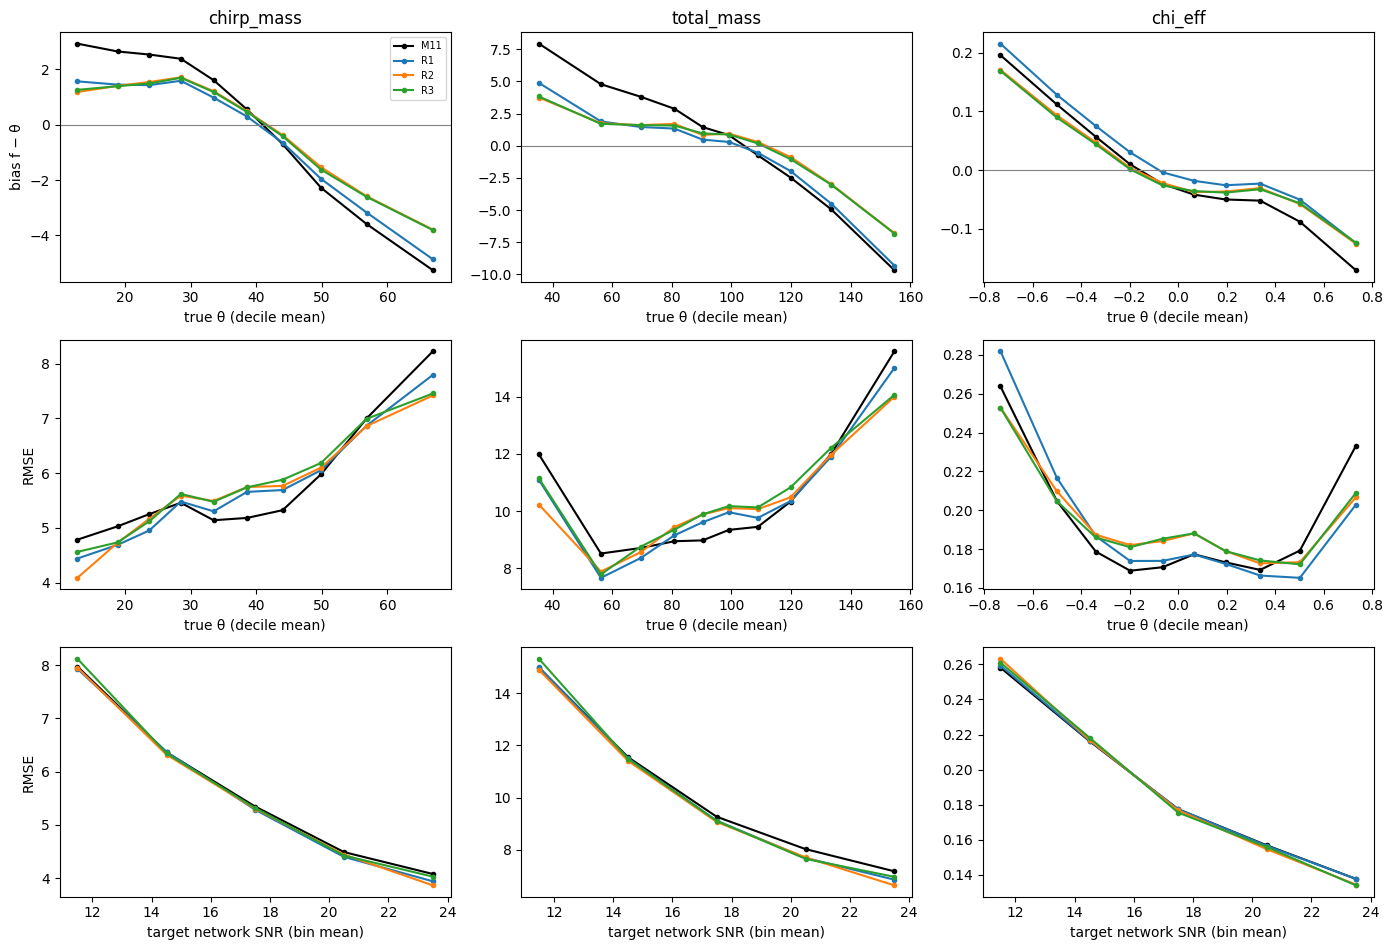

,model,label,bias_Q10,bias_Q90
0,M11,chirp_mass,2.9225,-5.2584
1,R1,chirp_mass,1.5618,-4.8627
2,R2,chirp_mass,1.1787,-3.7908
3,R3,chirp_mass,1.2547,-3.8085
4,M11,total_mass,7.9255,-9.6796
5,R1,total_mass,4.8742,-9.3181
6,R2,total_mass,3.7421,-6.798
7,R3,total_mass,3.8217,-6.8271
8,M11,chi_eff,0.19557,-0.17083
9,R1,chi_eff,0.21523,-0.12464


,model,snr_bin,snr_center,n,chirp_mass,total_mass,chi_eff
0,M11,"[10,13)",11.496,8084,7.9719,14.979,0.25814
1,M11,"[13,16)",14.51,8021,6.3588,11.545,0.21614
2,M11,"[16,19)",17.499,7945,5.3433,9.2704,0.17734
3,M11,"[19,22)",20.502,8073,4.4872,8.0306,0.15668
4,M11,"[22,25]",23.503,7877,4.0759,7.1808,0.13758
5,R1,"[10,13)",11.496,8084,7.9292,14.989,0.25934
6,R1,"[13,16)",14.51,8021,6.3672,11.5,0.21637
7,R1,"[16,19)",17.499,7945,5.2828,9.1172,0.1774
8,R1,"[19,22)",20.502,8073,4.3969,7.6932,0.15641
9,R1,"[22,25]",23.503,7877,3.9385,6.8606,0.13758


In [7]:
rows, tails = [], []
for j, lab in enumerate(LABELS):
    edges = np.quantile(Y[:, j], np.linspace(0, 1, 11))
    dec = np.clip(np.searchsorted(edges[1:-1], Y[:, j], side='right'), 0, 9)
    q10, q90 = edges[1], edges[9]
    for m in MODELS:
        r = P[m][:, j] - Y[:, j]
        for k in range(10):
            g = dec == k
            rows.append(dict(model=m, label=lab, decile=k + 1, center=Y[g, j].mean(), n=int(g.sum()),
                             bias=r[g].mean(), rmse=np.sqrt(np.mean(r[g]**2))))
        tails.append(dict(model=m, label=lab, bias_Q10=r[Y[:, j] <= q10].mean(), bias_Q90=r[Y[:, j] >= q90].mean()))
tab5_dec, tab5_tails = pd.DataFrame(rows), pd.DataFrame(tails)

tab5_snr = None
if SNR is not None:
    sbin = np.searchsorted(SNR_EDGES[1:-1], SNR, side='right')
    in_range = (SNR >= SNR_EDGES[0]) & (SNR <= SNR_EDGES[-1])
    print('rows outside SNR range:', int((~in_range).sum()))
    rows = []
    for m in MODELS:
        for b in range(len(SNR_EDGES) - 1):
            g = in_range & (sbin == b)
            rmse_b = np.sqrt(np.mean((P[m][g] - Y[g])**2, axis=0))
            rows.append(dict(model=m, snr_bin=f'[{SNR_EDGES[b]:g},{SNR_EDGES[b + 1]:g}{"]" if b == 4 else ")"}',
                             snr_center=SNR[g].mean(), n=int(g.sum()), **dict(zip(LABELS, rmse_b))))
    tab5_snr = pd.DataFrame(rows)

nrow = 3 if tab5_snr is not None else 2
fig, axes = plt.subplots(nrow, 3, figsize=(14, 3.2 * nrow))
for j, lab in enumerate(LABELS):
    for m in MODELS:
        t = tab5_dec[(tab5_dec.model == m) & (tab5_dec.label == lab)]
        axes[0, j].plot(t.center, t.bias, 'o-', ms=3, color=COLORS[m], label=m)
        axes[1, j].plot(t.center, t.rmse, 'o-', ms=3, color=COLORS[m])
        if tab5_snr is not None:
            t = tab5_snr[tab5_snr.model == m]
            axes[2, j].plot(t.snr_center, t[lab], 'o-', ms=3, color=COLORS[m])
    axes[0, j].axhline(0, color='0.5', lw=0.8)
    axes[0, j].set(title=lab, xlabel='true θ (decile mean)')
    axes[1, j].set(xlabel='true θ (decile mean)')
    if tab5_snr is not None:
        axes[2, j].set(xlabel='target network SNR (bin mean)')
axes[0, 0].set_ylabel('bias f − θ')
axes[1, 0].set_ylabel('RMSE')
if tab5_snr is not None:
    axes[2, 0].set_ylabel('RMSE')
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab5_tails)
    display(tab5_snr)

## 6. P4: degeneración M–χ_eff por decil de τ
τ30 newtoniano a partir de M_c verdadera y deciles exactamente como en M13.1. r = f − θ; M = total_mass. k = pendiente OLS de r_χ sobre
r_M en M11 (val global). Por modelo nuevo y decil: Δsesgo_χ = sesgo_χ − sesgo_χ(M11) frente a k·Δsesgo_M; P4: mismo signo en ≥ 8/10
deciles. Spearman(r_M, r_χ) global por modelo.

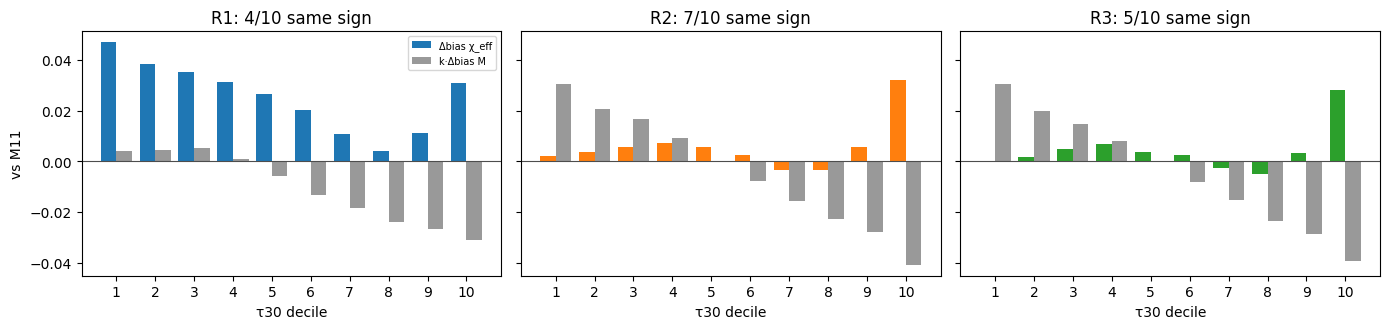

k (OLS r_chi on r_M, M11) = 0.010584


,"spearman(r_M, r_chi)"
M11,0.639734
R1,0.652425
R2,0.678850
R3,0.679574


{'R1': {'n_same_sign': 4, 'verdict': 'FALLA'},
 'R2': {'n_same_sign': 7, 'verdict': 'FALLA'},
 'R3': {'n_same_sign': 5, 'verdict': 'FALLA'}}

In [8]:
tau30 = tau_newtonian(Y[:, 0])
tau_edges = np.quantile(tau30, np.linspace(0, 1, 11))
tdec = np.clip(np.searchsorted(tau_edges[1:-1], tau30, side='right'), 0, 9)
R = {m: P[m] - Y for m in MODELS}
k_m11 = corr_row(R['M11'][:, 1], R['M11'][:, 2])['slope']
bias_tau = {m: np.array([R[m][tdec == d].mean(0) for d in range(10)]) for m in MODELS}

rows, verdict_p4 = [], {}
for m in NEW:
    dchi = bias_tau[m][:, 2] - bias_tau['M11'][:, 2]
    kdm = k_m11 * (bias_tau[m][:, 1] - bias_tau['M11'][:, 1])
    same = np.sign(dchi) == np.sign(kdm)
    for d in range(10):
        rows.append(dict(model=m, tau_decile=d + 1, tau_lo=tau_edges[d], tau_hi=tau_edges[d + 1],
                         d_bias_chi=dchi[d], k_d_bias_M=kdm[d], same_sign=bool(same[d])))
    verdict_p4[m] = dict(n_same_sign=int(same.sum()), verdict='PASA' if same.sum() >= P4_MIN_SAME else 'FALLA')
tab6 = pd.DataFrame(rows)
spearman = {m: corr_row(R[m][:, 1], R[m][:, 2])['spearman'] for m in MODELS}

fig, axes = plt.subplots(1, len(NEW), figsize=(14, 3.4), sharey=True)
x = np.arange(1, 11)
for ax, m in zip(axes, NEW):
    t = tab6[tab6.model == m]
    ax.bar(x - 0.2, t.d_bias_chi, 0.4, color=COLORS[m], label='Δbias χ_eff')
    ax.bar(x + 0.2, t.k_d_bias_M, 0.4, color='0.6', label='k·Δbias M')
    ax.axhline(0, color='0.3', lw=0.8)
    ax.set(title=f"{m}: {verdict_p4[m]['n_same_sign']}/10 same sign", xlabel='τ30 decile', xticks=x)
axes[0].set_ylabel('vs M11')
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()
print(f'k (OLS r_chi on r_M, M11) = {k_m11:.5g}')
display(pd.Series(spearman, name='spearman(r_M, r_chi)').to_frame())
verdict_p4

## 7. Resumen de veredictos

In [9]:
def to_json(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


g = tab1[tab1.model != 'M11']
summary = dict(
    experiment='M13.3a evaluation (val only)',
    inputs={k: dict(path=str(files[k]), sha256=sha[k]) for k in files},
    contract_identity=identity,
    checks=checks,
    settings=dict(labels=LABELS, residual='f - theta', units='physical (train-only M11 scaler)',
                  seed_pair=list(SEED_PAIR), guardrail_pct=GUARD_PCT, n_boot_rows=N_BOOT_ROWS,
                  seed_rows=SEED_ROWS, epoch_mark=EPOCH_MARK, slope_epochs=list(SLOPE_EPOCHS),
                  p1_range=list(P1_RANGE), p2_max=P2_MAX, c3_alphas=ALPHAS, c3_n_boot=C3_N_BOOT,
                  c3_seed=C3_SEED, c3_family_alpha=FAMILY_ALPHA, c3_margin_frac=MARGIN_FRAC,
                  p3_max_frac=P3_MAX_FRAC, p4_min_same=P4_MIN_SAME, snr_edges=SNR_EDGES,
                  snr_source=snr_source, n_val=len(Y), n_train40k=len(Y_TR), n_envs=len(np.unique(ENV))),
    metrics=tab1.to_dict('records'),
    bootstrap_rmse=tab1_boot.to_dict('records'),
    train40k_slopes_epochs=tab2.to_dict('records'),
    p1_p2=tab3.to_dict('records'),
    c3=tab4.to_dict('records'),
    c3_alphas=c3_alphas,
    tails=tab5_tails.to_dict('records'),
    deciles=tab5_dec.to_dict('records'),
    snr=None if tab5_snr is None else tab5_snr.to_dict('records'),
    p4=tab6.to_dict('records'),
    k_m11=k_m11,
    spearman_rM_rchi=spearman,
    verdicts=dict(
        guardrail={m: {l: v for l, v in zip(g[g.model == m].label, g[g.model == m].guardrail)} for m in NEW},
        resolved_rmse={m: {l: v for l, v in zip(g[g.model == m].label, g[g.model == m].resolved)} for m in NEW},
        P1=verdict_p1p2['P1_R2_R3'], P2=verdict_p1p2['P2_R2_R3'], P1_P2_per_run=verdict_p1p2['per_run'],
        P3=verdict_p3, P4=verdict_p4),
)
with open(SUMMARY_PATH, 'x') as fh:
    json.dump(summary, fh, indent=1, default=to_json)
print('saved', SUMMARY_PATH)
summary['verdicts']

saved /data/vserrano/cbc_pe_data/results/M13_3/M13_3a_evaluation_summary.json


{'guardrail': {'R1': {'chirp_mass': 'PASA',
   'total_mass': 'PASA',
   'chi_eff': 'PASA'},
  'R2': {'chirp_mass': 'PASA', 'total_mass': 'PASA', 'chi_eff': 'PASA'},
  'R3': {'chirp_mass': 'PASA', 'total_mass': 'PASA', 'chi_eff': 'PASA'}},
 'resolved_rmse': {'R1': {'chirp_mass': False,
   'total_mass': False,
   'chi_eff': False},
  'R2': {'chirp_mass': False, 'total_mass': False, 'chi_eff': False},
  'R3': {'chirp_mass': False, 'total_mass': False, 'chi_eff': False}},
 'P1': 'PASA',
 'P2': 'PASA',
 'P1_P2_per_run': {'R1': {'P1': 'FALLA', 'P2': 'PASA'},
  'R2': {'P1': 'PASA', 'P2': 'PASA'},
  'R3': {'P1': 'PASA', 'P2': 'PASA'}},
 'P3': {'M11': 'FALLA', 'R1': 'FALLA', 'R2': 'FALLA', 'R3': 'FALLA'},
 'P4': {'R1': {'n_same_sign': 4, 'verdict': 'FALLA'},
  'R2': {'n_same_sign': 7, 'verdict': 'FALLA'},
  'R3': {'n_same_sign': 5, 'verdict': 'FALLA'}}}

## Conclusiones M13.3a (27-10-2026)

**Verificado (val G1, 40 000 filas, emparejado por `idx`; ruido de semilla estimado solo con R2 frente a R3, 1 g.l.)**

1. **Salvaguarda:** PASA en R1, R2 y R3 y en las tres etiquetas. Ninguna diferencia de RMSE frente a M11 supera 2·|R2−R3|
   (ruido de semilla 1,3 / 1,7 / 0,2 % en [M_c, M, χ_eff]). El IC de bootstrap por filas mide solo el muestreo de val, no la
   variación entre semillas. Conclusión: el procedimiento corregido no cambia el RMSE global de forma resoluble.
2. **Contracción inducida por el entrenamiento: eliminada.** Pendiente θ sobre f en train40k: 0,999 en R2 y R3 (P1 PASA);
   en val pasa de 1,04–1,06 (M11) a 0,97–0,99 (P2 PASA). Mecanismo: dentro de cada ejecución, apagar el dropout (épocas
   64–79) lleva la pendiente en train de 1,01–1,06 a 0,999; en R1 (dropout activo) se queda en 1,02–1,03. Esto confirma
   M13.3.0: con dropout, la cabeza se ajusta a embeddings que no son los de inferencia. El planificador por sí solo (R1)
   reduce la contracción en train de ~0,07 a 0,02–0,035, pero no la elimina.
3. **Colas: menor regresión a la media, consistente en las dos semillas.** Sesgo con signo en Q10/Q90 frente a M11:
   M_c +2,9/−5,3 → +1,2/−3,8 M☉; M +7,9/−9,7 → +3,8/−6,8 M☉; χ_eff +0,196/−0,171 → +0,170/−0,125. Es el beneficio
   principal del procedimiento. Parte del sesgo condicionado a la verdad es irreducible (contracción del estimador bayesiano):
   esta reducción no indica cuánto falta hasta el óptimo.
4. **RMSE por SNR:** sin cambios en SNR < 16; en SNR ≥ 19, total_mass mejora un 3–7 % en R2/R3 (descriptivo, no resuelto).

**No concluido / pruebas fallidas**

5. **P3 FALLA.** El riesgo evitable de C3 sigue en 1,5–3,0 % (masas) y 1,0–1,5 % (χ_eff), y varía entre semillas
   (R2 1,5/1,2/1,0 %, R3 2,6/3,0/1,5 %). *Hipótesis:* lo que queda es sobre todo cambio de dominio de train a val (entornos
   PSD), no un artefacto de optimización. Apoyos: pendiente en train 0,999 frente a val 0,97–0,98, y MSE de train40k ~28 %
   menor que el de val. Sin verificar.
6. **P4 FALLA (4/7/5 de 10 deciles) y la prueba estaba mal planteada.** Los deciles de τ dependen de M_c, que está muy
   correlacionada con M, así que no separan la contracción de χ_eff de la degeneración M–χ_eff. Descriptivo: el Spearman
   (r_M, r_χ) sube de 0,64 (M11) a 0,68 (R2/R3); la degeneración pesa más en el error una vez quitado el sesgo sistemático.

**Decisión:** el procedimiento de R2/R3 pasa a ser la base de M13.3b (G3, semillas 123 y 124) y de M13.4. M11 sigue
congelado; los checkpoints nuevos no tienen conformal calibrado (los cuantiles de M11 no se reutilizan).